# Write UP

Course: CS 539

Name: Junhui Shi

Date: September 20, 2026

Milestone 3: Add in some Machine Learning

## Research Question

Muon optimizer exploits orthogonalization of update directions in gradient update matrices to achieve competitive performance against AdamW [1]. However, there is strong evidence that one source of Muon’s strong performance is its adaptive update geometry [2]. In particular, Muon approximates the polar transform of the gradient update matrix (G), i.e. G[t] = U[t] Σ[t] V[t]^T [3]. This update can also be interpreted as a steepest-descent update under an operator-norm geometry, where dualizing the gradient produces the polar factor U[t]V[t]^T [5]. Recent work has further generalized Muon-style spectral updates to constrained matrix geometries, including low-rank [6] and Stiefel-manifold settings [7], while related work has explored more efficient numerical solvers for manifold-constrained Muon updates [8]. It remains an open question how to adapt the polar transform based on the condition number or effective rank of the gradient update, which may vary across layers of a neural network [3]. By preventing over-flattening of well-conditioned singular values and updating directions, an optimizer designed around condition number could help suppress optimization noise and avoid slowing loss convergence. 
	The research question is: using a condition-number-adaptive variant of Muon that applies power-law interpolation between the gradient spectrum and polar normalization, with exponent αₜ determined by an efficiently estimated effective condition number κ̂(Mₜ), can we achieve at least 2–3% lower validation loss compared to vanilla Muon and AdamW, when training a 124M-parameter NanoGPT model on 300–400M tokens randomly sampled from FineWeb, while maintaining comparable training throughput (within 10% wall-clock time)?

## Hypothesis

A power-law spectral transformation of the momentum matrix,
Mₜ = Uₜ Σₜ Vₜᵀ,
ΔWₜ = −ηₜ cₜ Uₜ Σₜ^(1−αₜ) Vₜᵀ,
where αₜ ∈ [0, 1] controls the degree of spectral orthogonalization and cₜ normalizes the update magnitude, will improve optimization performance compared with complete orthogonalization (α = 1).
The adaptive exponent is determined by an approximate effective condition number:
κ̂ₜ = σ̂₉₅,ₜ / max(σ̂₅,ₜ, ε),
αₜ = 0, if κ̂ₜ ≤ κ₀,
αₜ = 1 − log(κ₀) / log(κ̂ₜ), if κ̂ₜ > κ₀,
where κ₀ > 1 is a tunable target condition number. This rule is proposed for empirical evaluation; it is not derived as an optimal policy.
For an exact spectrum with positive singular values, the power-law transformation satisfies:
κ(Σₜ^(1−αₜ)) = κ(Σₜ)^(1−αₜ).
We hypothesize that the optimal exponent frequently lies within 0 < α* < 1, with different layers and training tasks exhibiting different optimal values. Approximate condition-number estimation will enable layer-specific and time-dependent adaptation without requiring full SVD at every optimization step [17–19].


## Testable Claim

Condition-number-adaptive power-law spectral normalization can improve validation loss over optimization steps, tokens, and compute compared with vanilla Muon and AdamW. The proposed update ΔWₜ = −ηₜ cₜ Uₜ Σₜ^(1−αₜ) Vₜᵀ, where αₜ = f(κ̂ₜ) ∈ [0, 1], partially preserves the original singular-value distribution while controlling the degree of orthogonalization. We hypothesize that intermediate exponents (0 < α* < 1) yield better convergence in certain spectral regimes, and that optimal α varies across layers and training tasks.

### Independent variables:

Spectral exponent α ∈ {0, 0.25, 0.5, 0.75, 1}; adaptive exponent αₜ = f(κ̂ₜ); target condition number κ₀; spectral estimation method (exact SVD, Newton–Schulz spectral moments [17], randomized Krylov methods [18, 19]); adaptation frequency T ∈ {10, 50, 100, 200} steps; and optimizer configuration (AdamW, vanilla Muon, fixed-exponent Muon, adaptive Muon). Observed condition numbers κ(Gₜ), κ(Mₜ), κ(Wₜ), singular-value distributions, and network layer types will be analyzed as explanatory variables.

### Dependent variables:

For the primary experiment, validation loss after approximately 300–400M tokens, relative validation-loss improvement over vanilla Muon and AdamW (target ≥2–3%), and training throughput (within 10% wall-clock overhead). Secondary metrics include convergence speed (steps/tokens to target loss), optimal exponent α* across layers, spectral condition numbers before and after transformation, approximate condition-number estimation error relative to exact SVD, and computational overhead. Report validation loss at fixed token and compute budgets as the mean over 3–5 paired seeds with 95% confidence intervals. Pilot-run variance will determine whether additional seeds are required to detect the targeted improvement at 80% statistical power.

### Control:

Model size (124M parameters, 12 layers, 768 hidden dimensions, 12 attention heads); dataset (FineWeb subset, approximately 367M tokens); compute budget (8 × H100, approximately 1 hour wall-clock per baseline run); batch size (512 sequences × 1,024 tokens = 524,288 tokens per step); training length (700 steps ≈ 367M tokens); learning-rate schedule (no warmup, constant peak learning rate followed by linear warmdown over the final 200 steps, with optimizer-specific learning rates calibrated using the same tuning protocol); momentum configuration (0.95 with Nesterov for Muon variants); optimizer split (Muon variants on transformer weight matrices and AdamW on lm_head); data order and sampling (fixed shard order); initialization (identical across paired runs); precision (bfloat16 autocast, torch.compile); and evaluation procedure (FineWeb validation split, evaluated every 50 steps), held consistent across the optimizer comparisons [9]. Spectral estimation and normalization methods will be held fixed when isolating the effect of α.

### Ho: Null Hypothesis:

Condition-number-adaptive power-law spectral normalization provides no statistically significant improvement in validation loss over vanilla Muon and AdamW at matched token or compute budgets. The optimal exponent α* exhibits no reproducible dependence on spectral condition numbers or network layers.

### Ha: Alternative Hypothesis:

Condition-number-adaptive power-law spectral normalization achieves at least 2–3% lower validation loss than vanilla Muon and AdamW at matched token budgets while maintaining training throughput within 10% of vanilla Muon. Intermediate optimal exponents (0 < α* < 1) occur in identifiable spectral regimes, and α* varies systematically with condition number, network layer, or training stage.

## Implementation Details — Efficient Approximate Condition-Number Estimation

### 1. Momentum computation

For each weight matrix Wₜ, compute exponential moving-average momentum (β = 0.95 by default), without Nesterov momentum:
Mₜ = βMₜ₋₁ + (1 − β)Gₜ.
Vanilla Muon approximates the polar factor UₜVₜᵀ using Newton–Schulz iterations without explicitly calculating singular values [1, 5].

### 2. Spectral-moment extraction

Normalize each momentum matrix in float32, using ε = 10⁻⁷ to guard the norm, and transpose if necessary so the Gram matrix uses the smaller dimension:
X = Mₜ / max(‖Mₜ‖F, ε), A = XXᵀ, r = min(m, n).
Extract only the second and fourth spectral moments:
m₂ = tr(A) / r, m₄ = ‖A‖F² / r.
The adaptive optimizer does not extract moments from Newton–Schulz iterations.

### 3. Estimate the effective condition number

The implementation uses a log-normal moment-based proxy, rather than fitting a maximum-entropy distribution or directly computing quantiles:
ρ = max(m₄ / max(m₂², float32 tiny), 1), log κ̂ₜ = 1.64485 √(log ρ).
This proxy is not guaranteed to recover the true condition number; moment-based estimates can miss isolated small singular values. Exact-SVD and alternative-estimator comparisons are possible future validation, not part of this implementation.

### 4. Adaptive spectral transformation

Compute αₜ = 0 when log κ̂ₜ ≤ log κ₀; otherwise αₜ = 1 − log κ₀ / log κ̂ₜ, clamped to [0, 1], with κ₀ = 10 by default. For X = UΣVᵀ, the desired normalized-momentum transform is Pₜ = UΣ^(1−αₜ)Vᵀ.
The implementation approximates (A + 0.01²I)^(−αₜ/2)X with a degree-32 Chebyshev polynomial, using the smaller Gram matrix and restoring the original orientation. The spectral floor regularizes the transform, and the approximation may be inaccurate near zero; no exact SVD is used in adaptive updates.

### 5. Update normalization

Normalize the transformed update to a target Frobenius norm √r when its norm is at least ε:
cₜ = √r / max(‖Pₜ‖F, ε)
Wₜ₊₁ = Wₜ − ηₜ cₜ Pₜ

### 6. Adaptation and validation

Recompute the moments and αₜ on every optimizer step for each matrix; stacked 3:1 attention matrices are split into three blocks and transformed separately. The optimizer stores α values in its state, but does not log the condition-number proxy or perform periodic exact-SVD validation. Training logs record loss and training time, excluding validation and checkpointing.

## Dataset Description and Details

Experiments to demonstrate competitive behaviors with our conditioned aware polar update design is to NanoGPT speedrun with decoder only (124M parameters, 768 vector embeddings and 12 attention head) with FineWeb Dataset (with Vanilla muon or other previously proposed SOTA optimizer variants as control) [4, 9, 10]. 

For FineWeb Dataset (Penedo et al.), it is an open source web documents dataset specially curated for training large language models by the CommonCrawl foundation. The documents span diverse domains (from government, legal, academic to informal news and commerce) and geographic regions. The total size of the dataset is roughly 18.5T-token, and gathered from the year 2013 to 2024. However, we want to use only a subset of it to streamline our optimizer experiments (i.e. around 300-400M tokens, randomly sampled from FineWeb training shards in accordance with standard train/test split strategy for NanoGPT Speedrun). The dataset is hosted under the ODC-By 1.0 license in HuggingFace. We chose FineWeb for its quality filtering, deduplication, and use in the NanoGPT/Muon benchmarks, which lets us compare against published baselines. C4 is smaller and older [11] , The Pile is heterogeneous [12], and RedPajama is larger and less filtered [13]. Results may not generalize beyond web text; we will add a second source only if the compute budget allows.

Subset statistics: On our 100,000-document subset, length was measured as whitespace-split words per document, giving 1.09% abnormally short documents (52 words or fewer, the 1st percentile) and about 31% possibly truncated. Domain balance was measured as the spread of documents across URL hostnames (imbalance score 0.03, top-5 hostnames covering 0.48% of documents), and quality issues as 0.06% of documents with corrupted (replacement) characters, no missing metadata fields, and a FineWeb-Edu classifier score per document.

We ran exploratory data analysis on the 100,000-document subset covering text-length distribution, truncated and corrupted documents, URL-domain balance, topic-classifier confidence, embedding-space cluster balance (KMeans, k=400), FineWeb-Edu quality scores, and missing metadata.

### EDA Results:

| Area | Result |
| --- | --- |
| **Subset size** | 100,000 docs, ~69.2M tokens |
| **Length (words)** | 0 empty; 1,091 (1.09%) abnormally short, below the 1st percentile = 52 words. Heavy right tail up to ~42k words. |
| **Truncation** | 29,204 (29.2%) documents are apparently truncated (i.e. they don't end in terminal punctuation after trailing quotes or brackets are stripped). |
| **Domain balance** | Imbalance score 0.03, HHI ~ 0.00, top-5 share 0.48%. Domains are very evenly spread, with no single source (the largest, Wikipedia, is only about 0.12% of documents) dominating the subset, so source-specific bias is unlikely to affect the optimizer comparison. |
| **Topic balance** | Imbalance 0.156, HHI 0.108, top-5 share 61.7%. Mean classifier confidence 0.806, median 0.863, Q1 0.708, Q3 0.950. 8.47% of docs have confidence below 0.5. The topic distribution is moderately imbalanced: the five largest topics (news, business, daily life, science and technology, arts and culture) cover about 62% of documents, while the three smallest (relationships, youth and student life, family) each have fewer than about 250 documents, so the optimizer is trained mostly on news and business text. The domain-level imbalance is almost zero (0.03). |
| **Missing fields** | 0% for text, url, date, dump, language and quality. Since FineWeb is processed and filtered, missing fields are handled accordingly [4, 14]. |
| **Corruption** | 60 docs (0.06%) have 296 replacement characters in total. No control or surrogate characters. |
| **Clusters** | k=400 KMeans on bge-base-en-v1.5 embeddings. Cluster sizes run from 72 to 597 [16]. |
| **Quality vs. diversity (400 clusters)** | Scored with the FineWeb-Edu classifier. Clusters are binned into 5×5 quintiles and are spread across every cell (about 10-24 each). Low-quality clusters skew toward low diversity (31 clusters in the lowest-quality / lowest-diversity cell, versus 2 in the highest-quality / lowest-diversity cell). Quality and diversity vary widely across clusters, with low quality concentrated in a minority of narrow, low-diversity clusters. |


## Preliminary Experiments

Three preliminary NanoGPT runs compare AdamW, vanilla Muon, and ConditionalNumberAdaptiveMuon. Each trains a randomly initialized GPT-2-style decoder (12 layers, width 768, 12 heads, vocabulary 50,257) using FineWeb10B binary shards, PyTorch DDP, compilation, bfloat16 autocast, and an NVIDIA H100 80 GB GPU. The configured global batch is 512 sequences of 1,024 tokens. AdamW ran 9,536 steps with 5.1B training tokens available; each Muon variant ran 6,200 steps with 3.3B available. Each run had a 100M-token validation shard, with validation logged every 125 steps and at the start and end. These are single runs with different training budgets, not matched-budget or multi-seed comparisons.

Run artifacts are in [AdamW](../runpod-results/20261108-071147-91210-14344/), [Muon](../muon-full/), and [ConditionalNumberAdaptiveMuon](../runpod-results/20261108-110947-67696-13584/). Each directory contains `training.log` and `logs/<run-id>.txt`, with a final checkpoint at `logs/<run-id>/state_step*.pt`. The `.txt` log begins with a copy of the experiment's training script, followed by environment details and recorded losses and timings; the `.pt` checkpoint also stores the script, step, model state, and optimizer states.

The recorded scripts configure AdamW over all parameters at learning rate 0.0018, β=(0.9, 0.95), and zero weight decay. Both Muon runs use AdamW for the output head at 0.0036 and Muon for transformer blocks at 0.00036 with momentum 0.95. The adaptive variant estimates spectral moments every step, using κ₀=10 and a degree-32 polynomial with spectral floor 0.01. Script defaults specify 250 warmup and 2,000 warmdown steps for AdamW, no warmup and 1,800 warmdown steps for Muon, and no warmup and 10 warmdown steps for the adaptive run; command-line overrides are not recorded in the logs. The logged training timer excludes the first 10 steps, validation, and checkpointing.

At their final checkpoints, AdamW reached validation loss 3.2790 at 9,536 steps, Muon 3.2776 at 6,200 steps, and ConditionalNumberAdaptiveMuon 3.7021 at 6,200 steps. Their logged average step durations were 1,154.05, 1,191.35, and 1,408.53 ms, respectively; the adaptive run was about 18.2% slower per step than Muon. These final losses are not a matched-step comparison because AdamW ran longer; each result is from a single run. At 6,200 steps, adaptive Muon's validation loss was approximately 13.0% higher than vanilla Muon's. AdamW and Muon ended at nearly the same validation loss, although at different step counts, while AdamW had the lowest average step duration. At the shortest run's final logged training time (122.91 minutes), validation loss was 3.2776 for Muon, approximately 3.4185 for AdamW, and 3.7508 for adaptive Muon. AdamW and adaptive Muon values are linearly interpolated between adjacent validation measurements; this is logged training time, not total wall-clock time.

The NanoGPT speedrun uses a FineWeb validation-loss target of 3.28 [1]. AdamW first logged a loss at or below this target at step 9,500 (182.53 minutes of logged training time), and Muon at step 6,125 (121.43 minutes); these reproduce the target value but not necessarily the published speedrun timing or full protocol. These times exclude the first 10 steps, validation, and checkpointing, and are not total wall-clock times. ConditionalNumberAdaptiveMuon did not reach 3.28 within its 6,200-step run; it is a preliminary implementation with limited tuning and compute budget, so further optimization and evaluation are needed to determine whether it can reach the target.

## Next Steps

1. **Build a cheaper testbed:** Train smaller models from scratch on a lower-cost GPU setup, using [SimpleStories-5M](https://huggingface.co/SimpleStories/SimpleStories-5M) (5.37M parameters, 6 layers, hidden dimension 256) [20] or [SimpleStories-11M](https://huggingface.co/SimpleStories/SimpleStories-11M) (11M parameters, 6 layers, hidden dimension 384) [21] configurations; use matched data, token budgets, and multiple seeds for rapid comparisons. The linked model cards also provide pretrained weights. Use FineWeb [4, 14] instead of the SimpleStories dataset [22] for controlled comparisons with the preliminary experiments.
2. **Map the exponent:** Sweep fixed α values in [0, 1] to test whether an optimum α* exists and whether it varies by layer or training stage; compare with adaptive α and baseline optimizers.
3. **Analyze and ablate components:** Inspect spectral moments, estimated condition numbers, α, update norms, approximation error against exact SVD, loss, and overhead. Vary κ₀, estimation frequency, polynomial degree, spectral floor, momentum, and update normalization one at a time.
4. **Tune training:** Sweep base learning rates, warmup and warmdown schedules, weight decay, and other optimizer hyperparameters using a consistent tuning budget.
5. **Explore α > 1:** Extend the exponent range beyond the current clamp and test stability and validation loss against the [0, 1] sweep.
6. **Ablate optimizer placement:** Assign different optimizers to attention, MLP, embedding, and output layers to measure each component's contribution.
7. **Reassess the goal:** If condition-adaptive updates do not outperform Muon on the speedrun, pivot the hypothesis toward understanding when and where partial spectral orthogonalization improves optimization.

## Alternative Hypothesis 

### Hypothesis 1 — Training-Regime Dependence

Partial spectral orthogonalization with fixed exponent α ∈ 1 will improve validation loss by ≥1% over vanilla Muon (α = 1) during fine-tuning, but not necessarily during pretraining, under matched token budgets and independently tuned learning rates. We hypothesize that the optimal exponent satisfies 0 < α* < 1 during fine-tuning, with results reproducible across 3–5 seeds.

### Hypothesis 2 — Layer-Dependent Spectral Orthogonalization

Layer-specific power-law spectral updates, ΔWₗ = −η cₗ UₗΣₗ^(1−αₗ)Vₗᵀ, will achieve ≥1% lower validation loss than vanilla Muon on 124M-parameter NanoGPT trained on 367M FineWeb tokens, while maintaining ≤10% training-time overhead. We hypothesize that optimal exponents differ by ≥0.25 across at least two layer groups, and selective partial orthogonalization outperforms uniform α = 1 across 3–5 paired seeds.

### Hypothesis 3 — Spectral Geometry and Descent Efficiency

The effectiveness of partial spectral orthogonalization is better predicted by local descent efficiency than by the momentum matrix's condition number alone. We hypothesize that a model incorporating measured loss decrease per unit update norm will predict the best exponent among α ∈ 1 with ≥70% held-out selection accuracy, exceeding a condition-number-only predictor by ≥10 percentage points, across at least three neural-network architectures.

## References

[1] Jordan, K., Jin, Y., Boza, V., You, J., Cesista, F., Newhouse, L., & Bernstein, J. (2024). Muon: An optimizer for hidden layers in neural networks.
https://kellerjordan.github.io/posts/muon/

[2] Shumaylov, Z., Da Costa, N., Zaika, P., Mucsányi, B., Massucco, A., Gelberg, Y., Schönlieb, C.-B., Gal, Y., & Hennig, P. (2026). Muon is Not That Special: Random or Inverted Spectra Work Just as Well. arXiv:2605.11181.
https://arxiv.org/abs/2605.11181

[3] Beneventano, P., Abdelmoneum, M., & Poggio, T. (2026). The Spectral Dynamics and Noise Geometry of Muon. arXiv:2606.08388.
https://arxiv.org/abs/2606.08388

[4] Penedo, G., Kydlíček, H., Ben Allal, L., Lozhkov, A., Mitchell, M., Raffel, C., Von Werra, L., & Wolf, T. (2024). The FineWeb Datasets: Decanting the Web for the Finest Text Data at Scale. Advances in Neural Information Processing Systems, 37, Datasets and Benchmarks Track.
https://proceedings.neurips.cc/paper_files/paper/2024/hash/370df50ccfdf8bde18f8f9c2d9151bda-Abstract-Datasets_and_Benchmarks_Track.htm

[5] Bernstein, J. (2025). Deriving Muon.
https://jeremybernste.in/writing/deriving-muon

[6] Cesista, F. L., Crowson, K., Simal, C., & Biderman, S. (2026). LoRA-Muon: Spectral Steepest Descent on the Low-Rank Manifold. arXiv:2606.12921.
https://www.alphaxiv.org/pdf/2606.12921

[7] Solonko, M., Alexander, M., & Rakhuba, M. (2026). Muon on the Stiefel Manifold Admits an Exact Closed-Form Update. arXiv:2608.06218.
https://arxiv.org/abs/2608.06218

[8] Buchanan, S. D. (2025). A Faster Manifold Muon with ADMM.
https://sdbuchanan.com/blog/manifold-muon/

[9] Jordan, K., et al. modded-nanogpt: NanoGPT speedrun. GitHub. https://github.com/KellerJordan/modded-nanogpt

[10] Karpathy, A. nanoGPT. GitHub. https://github.com/karpathy/nanoGPT

[11] Raffel, C., et al. (2019). Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer. arXiv:1910.10683. https://arxiv.org/abs/1910.10683

[12] Gao, L., et al. (2020). The Pile: An 800GB Dataset of Diverse Text for Language Modeling. arXiv:2101.00027. https://arxiv.org/abs/2101.00027

[13] Weber, M., et al. (2024). RedPajama: an Open Dataset for Training Large Language Models. arXiv:2411.12372. https://arxiv.org/abs/2411.12372

[14] HuggingFaceFW. FineWeb dataset card. Hugging Face. https://huggingface.co/datasets/HuggingFaceFW/fineweb

[15] Loshchilov, I., & Hutter, F. (2017). Decoupled Weight Decay Regularization. arXiv:1711.05101. https://arxiv.org/abs/1711.05101

[16] Xiao, S., et al. (2023). C-Pack: Packed Resources For General Chinese Embeddings. arXiv:2309.07597. https://arxiv.org/abs/2309.07597

[17] Topollai, K., & Choromanska, A. (2026). Cost-free Spectral Estimation for Adaptive Newton–Schulz in Matrix Optimizers. arXiv:2609.33047. (Preprint.)
https://arxiv.org/abs/2609.33047

[18] Avron, H., Druinsky, A., & Toledo, S. (2019). Spectral condition-number estimation of large sparse matrices. Numerical Linear Algebra with Applications, 26(3), e2235.
https://doi.org/10.1002/nla.2235

[19] Gaaf, S. W., & Hochstenbach, M. E. (2015). Probabilistic bounds for the matrix condition number with extended Lanczos bidiagonalization. SIAM Journal on Scientific Computing, 37(5), S581–S601.
https://doi.org/10.1137/140975218

[20] SimpleStories. SimpleStories-5M model card. Hugging Face. https://huggingface.co/SimpleStories/SimpleStories-5M

[21] SimpleStories. SimpleStories-11M model card. Hugging Face. https://huggingface.co/SimpleStories/SimpleStories-11M

[22] Finke, L. SimpleStories dataset card. Hugging Face. https://huggingface.co/datasets/lennart-finke/SimpleStories

[23] Dong, Y., & Sawin, W. (2026). Muon^p: Muon with Fractional Spectral Powers. arXiv:2606.13867. https://arxiv.org/abs/2606.13867

# Analysis of Training Runs

After starting or restarting the kernel, run the setup cells below in order (or select **Run All**) before running the results or plot cells.

In [1]:
import re
from collections import deque
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt

In [2]:
"""Plot the training and validation losses recorded by the three runs."""
def find_record_directory():
    relative = Path("modded-nanogpt/records/track_1_short/2024-10-10_Muon")
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent, parent / relative):
            if (candidate / "muon-full/training.log").is_file():
                return candidate
    raise FileNotFoundError("Could not find the 2024-10-10_Muon record directory from the notebook working directory")

In [3]:
RECORD = find_record_directory()
FILES = {
    "AdamW": RECORD / "runpod-results/20261108-071147-91210-14344/training.log",
    "Muon": RECORD / "muon-full/training.log",
    "ConditionalNumberAdaptiveMuon": (
        RECORD / "runpod-results/20261108-110947-67696-13584/training.log"
    ),
}
COLORS = {
    "AdamW": "tab:blue",
    "Muon": "tab:purple",
    "ConditionalNumberAdaptiveMuon": "tab:orange",
}
LOG_LINE = re.compile(
    r"^step:(\d+)/\d+ (train_loss|val_loss):"
    r"([0-9.eE+-]+) train_time:(\d+)ms step_avg:([0-9.eE+-]+|nan)ms"
)

In [4]:
@dataclass
class Run:
    train: list
    val: list
    step_ms: float
    last_val_step: int


def read_run(path):
    train = []
    val = []
    step_ms = None
    last_val_step = None
    with path.open(encoding="utf-8") as log:
        for line in log:
            match = LOG_LINE.match(line)
            if not match:
                continue
            step, kind, loss, time_ms, average = match.groups()
            # The logged clock is reset at step 10; earlier times are not comparable.
            if int(step) <= 10:
                continue
            point = (int(time_ms) / 60000, float(loss))
            (train if kind == "train_loss" else val).append(point)
            if kind == "val_loss":
                last_val_step = int(step)
            if average != "nan":
                step_ms = float(average)
    if not train or not val or step_ms is None or last_val_step is None:
        raise ValueError(f"Missing training, validation, or timing data in {path}")
    return Run(train, val, step_ms, last_val_step)


def smooth(points, window=50):
    """Return a trailing mean of training loss at each logged time."""
    recent = deque()
    total = 0.0
    result = []
    for time_minutes, loss in points:
        recent.append(loss)
        total += loss
        if len(recent) > window:
            total -= recent.popleft()
        result.append((time_minutes, total / len(recent)))
    return result


def common_validation_time(runs):
    return min(run.val[-1][0] for run in runs.values())


def validation_loss_at_time(points, time):
    for index, (current_time, loss) in enumerate(points):
        if current_time == time:
            return loss, False
        if current_time > time and index > 0:
            previous_time, previous_loss = points[index - 1]
            fraction = (time - previous_time) / (current_time - previous_time)
            return previous_loss + fraction * (loss - previous_loss), True
    raise ValueError(f"Validation time {time} is outside the logged range")


def plot_loss_vs_epochs(runs, kind):
    fig, ax = plt.subplots(figsize=(8, 5))
    for name, run in runs.items():
        points = smooth(run.train) if kind == "train" else run.val
        times, losses = zip(*points)
        ax.plot(
            times,
            losses,
            color=COLORS[name],
            linewidth=1.8,
            marker="." if kind == "val" else None,
            markersize=4,
            label=f"{name}  ({run.step_ms:.0f} ms/step)",
        )
    if kind == "val":
        common_time = common_validation_time(runs)
        ax.axvline(common_time, color="black", linestyle="--", linewidth=1.2,
                   label=f"Shortest run: {common_time:.2f} min")
    ax.set_title(f"Optimizer comparison by time: {kind} loss")
    ax.set_xlabel("Logged training time (minutes)")
    ax.set_ylabel(f"{kind.capitalize()} loss")
    ax.set_ylim(3.0, 4.2)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
    note = (
        "Loss outside 3.0-4.2 is clipped. Timing excludes the first 10 steps, "
        "validation, and checkpointing."
    )
    if kind == "train":
        note += " Training loss: trailing 50-step mean."
    fig.text(0.5, 0.015, note, ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()


runs = {name: read_run(path) for name, path in FILES.items()}


In [5]:
def experimental_results(runs):
    for name, run in runs.items():
        print(f"- {name}: final validation loss {run.val[-1][1]:.4f} "
              f"at step {run.last_val_step:,}; average {run.step_ms:.2f} ms/step.")
        reached = next(((time, loss) for time, loss in run.val if loss <= 3.28), None)
        if reached is None:
            print(f"- {name}: validation loss 3.28 not reached in logged measurements.")
        else:
            time, loss = reached
            print(f"- {name}: first logged validation loss at or below 3.28: "
                  f"{loss:.4f} at {time:.2f} minutes.")

    muon = runs["Muon"]
    adaptive = runs["ConditionalNumberAdaptiveMuon"]
    print(f"- Adaptive Muon average step duration vs. Muon: "
          f"{(adaptive.step_ms / muon.step_ms - 1) * 100:+.1f}%.")
    if adaptive.last_val_step == muon.last_val_step:
        print(f"- Adaptive Muon validation loss vs. Muon at step "
              f"{muon.last_val_step:,}: "
              f"{(adaptive.val[-1][1] / muon.val[-1][1] - 1) * 100:+.1f}%.")
    else:
        print("- Muon and adaptive Muon final validation steps differ; "
              "their final losses are not a matched-step comparison.")
    common_time = common_validation_time(runs)
    print(f"- Shortest final logged validation time: {common_time:.2f} minutes.")
    for name, run in runs.items():
        loss, interpolated = validation_loss_at_time(run.val, common_time)
        method = "linearly interpolated" if interpolated else "logged"
        print(f"- {name} validation loss at that time: {loss:.4f} ({method}).")
    print("- Logged timing excludes the first 10 steps, validation, and checkpointing.")


if not all(name in globals() for name in ("runs", "common_validation_time", "validation_loss_at_time")):
    raise RuntimeError("Run the preceding setup cells in order or select Run All before computing results.")
experimental_results(runs)

- AdamW: final validation loss 3.2790 at step 9,536; average 1154.05 ms/step.
- Muon: final validation loss 3.2776 at step 6,200; average 1191.35 ms/step.
- ConditionalNumberAdaptiveMuon: final validation loss 3.7021 at step 6,200; average 1408.53 ms/step.
- Adaptive Muon average step duration vs. Muon: +18.2%.
- Adaptive Muon validation loss vs. Muon at step 6,200: +13.0%.
- Shortest final logged validation time: 122.91 minutes.
- AdamW validation loss at that time: 3.4185 (linearly interpolated).
- Muon validation loss at that time: 3.2776 (logged).
- ConditionalNumberAdaptiveMuon validation loss at that time: 3.7508 (linearly interpolated).
- Logged timing excludes the first 10 steps, validation, and checkpointing.


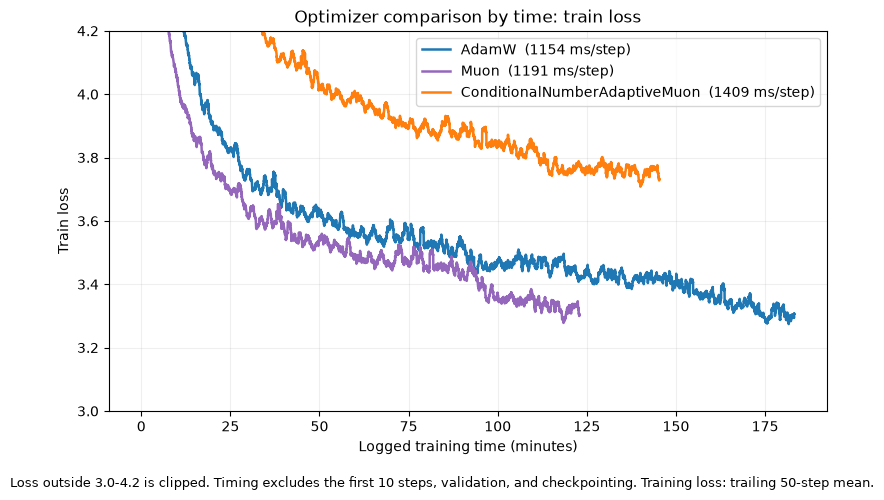

In [6]:
plot_loss_vs_epochs(runs, "train")


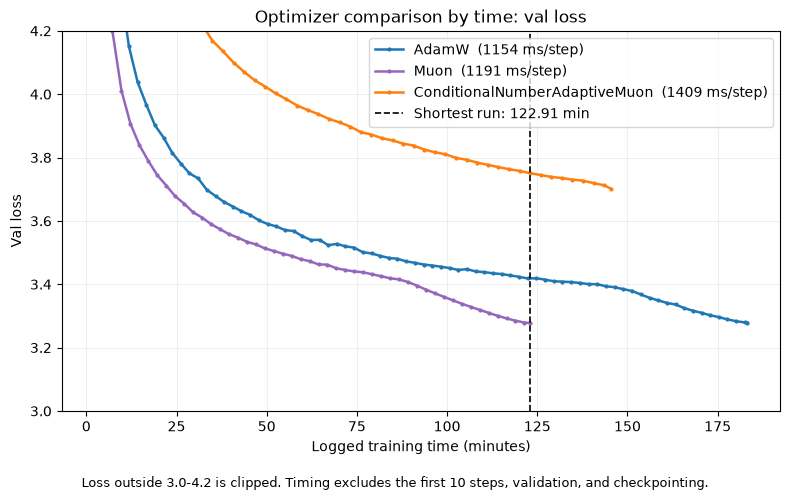

In [7]:
plot_loss_vs_epochs(runs, "val")


In [8]:
def plot_per_step_duration_ms(runs):
    names = list(runs)
    averages = [runs[name].step_ms for name in names]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.barh(names, averages, color=[COLORS[name] for name in names])
    ax.invert_yaxis()
    ax.set_xlabel("Average training step duration (ms)")
    ax.set_title("Optimizer comparison: average step duration")
    ax.set_xlim(0, max(averages) * 1.18)
    for bar, average in zip(bars, averages):
        ax.text(average + max(averages) * 0.02, bar.get_y() + bar.get_height() / 2,
                f"{average:.2f} ms", va="center")
    fig.text(0.5, 0.01, "Logged average; excludes first 10 steps, validation, and checkpointing.",
             ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()

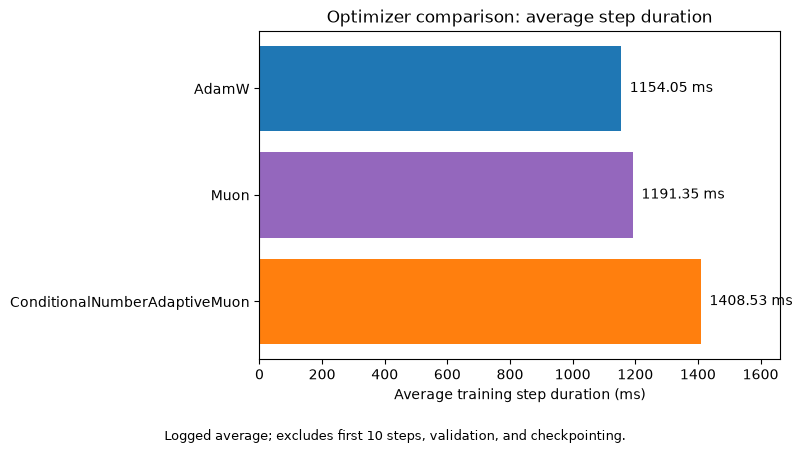

In [9]:
plot_per_step_duration_ms(runs)